In [1]:
import os

import pandas as pd
import numpy as np
from Bio import Phylo

data_dir = "../../data/tree"
out_dir = "../../out"

tree = Phylo.read(os.path.join(data_dir, "cstart.fastree.treefile"), "newick")
df = pd.read_csv(os.path.join(data_dir, "tree_data.csv"))
data_map = df.set_index("accession").to_dict("index")

all_terminals = tree.get_terminals()
data_terminals = [t for t in all_terminals if t.name in data_map]
print(f"Tree leaves: {len(all_terminals)}, in dataset: {len(data_terminals)}")

names = [t.name for t in data_terminals]
n = len(names)
print(f"Computing {n}x{n} distance matrix...")

dist_matrix = np.zeros((n, n))
for i in range(n):
    for j in range(i + 1, n):
        d = tree.distance(data_terminals[i], data_terminals[j])
        dist_matrix[i, j] = d
        dist_matrix[j, i] = d


np.fill_diagonal(dist_matrix, np.inf)

valid_3oh_idx = [i for i, name in enumerate(names) if not pd.isna(data_map[name]["3OH"])]
print(f"Leaves with valid 3OH: {len(valid_3oh_idx)}")

results = []
for i, name in enumerate(names):
    nn_idx = int(np.argmin(dist_matrix[i]))
    nn_name = names[nn_idx]
    nn_dist = dist_matrix[i, nn_idx]

    row_3oh = dist_matrix[i].copy()
    all_idx = set(range(n))
    invalid_3oh_idx = all_idx - set(valid_3oh_idx)
    row_3oh[list(invalid_3oh_idx)] = np.inf
    nn_3oh_idx = int(np.argmin(row_3oh))
    nn_3oh_name = names[nn_3oh_idx]

    true_info = data_map[name]
    pred_info = data_map[nn_name]
    pred_3oh_info = data_map[nn_3oh_name]

    results.append({
        "accession": name,
        "true_category": true_info["category"],
        "true_3OH": true_info["3OH"],
        "nearest_neighbor": nn_name,
        "nn_distance": nn_dist,
        "pred_category": pred_info["category"],
        "nn_3oh": nn_3oh_name,
        "pred_3OH": pred_3oh_info["3OH"],
    })

results_df = pd.DataFrame(results)
results_df.to_csv(os.path.join(out_dir, "tree_predictions.csv"), index=False)
results_df.head()


Tree leaves: 206, in dataset: 202
Computing 202x202 distance matrix...
Leaves with valid 3OH: 122


,accession,true_category,true_3OH,nearest_neighbor,nn_distance,pred_category,nn_3oh,pred_3OH
0,CS0002581,SCFA,NaN,CS0000346,1.233297,SCFA,CS0001203,0.0
1,CS0000346,SCFA,NaN,CS0001203,0.672758,LCFA,CS0001203,0.0
2,CS0001203,LCFA,0.0,CS0000346,0.672758,SCFA,CS0001574,0.0
3,CS0000296,AR,NaN,CS0002373,0.893288,AR,CS0000997,0.0
4,CS0002373,AR,NaN,CS0000296,0.893288,AR,CS0000997,0.0


=== Aromatic vs Non-Aromatic Prediction ===
Accuracy: 0.926
              precision    recall  f1-score   support

      non-AR       0.99      0.90      0.94       135
          AR       0.82      0.99      0.90        67

    accuracy                           0.93       202
   macro avg       0.91      0.94      0.92       202
weighted avg       0.94      0.93      0.93       202



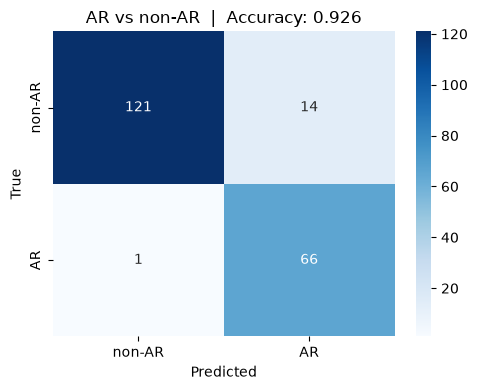

In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns

# --- Aromatic prediction: AR vs non-AR ---
ar_df = results_df.copy()
ar_df["true_AR"] = (ar_df["true_category"] == "AR").astype(int)
ar_df["pred_AR"] = (ar_df["pred_category"] == "AR").astype(int)

y_true = ar_df["true_AR"]
y_pred = ar_df["pred_AR"]

labels = ["non-AR", "AR"]
cm = confusion_matrix(y_true, y_pred)
acc = accuracy_score(y_true, y_pred)

print("=== Aromatic vs Non-Aromatic Prediction ===")
print(f"Accuracy: {acc:.3f}")
print(classification_report(y_true, y_pred, target_names=labels))

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"AR vs non-AR  |  Accuracy: {acc:.3f}")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "confusion_ar.png"), dpi=150)
plt.show()


Entries with size categories: 134
Entries where NN also has size category: 120
Accuracy (size categories only): 0.783
              precision    recall  f1-score   support

        LCFA       0.85      0.86      0.85        70
        MCFA       0.71      0.68      0.70        22
        SCFA       0.68      0.68      0.68        28

    accuracy                           0.78       120
   macro avg       0.75      0.74      0.74       120
weighted avg       0.78      0.78      0.78       120



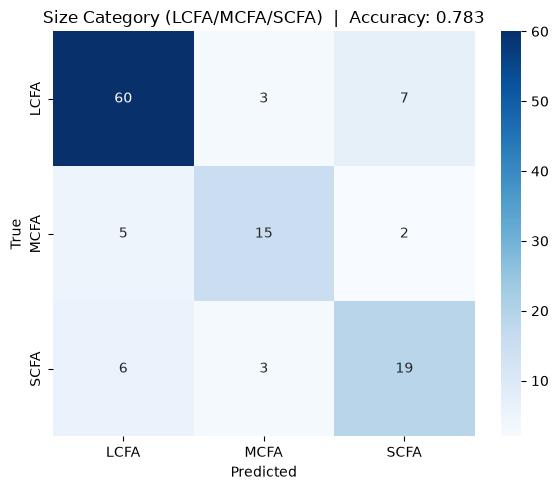

In [3]:
# --- Size prediction: LCFA vs MCFA vs SCFA (exclude AR and FA) ---
size_cats = {"SCFA", "MCFA", "LCFA"}

# Keep only rows where true category is a size category
size_df = results_df[results_df["true_category"].isin(size_cats)].copy()
print(f"Entries with size categories: {len(size_df)}")

# For entries whose NN is outside size cats, report as-is
size_df["pred_size"] = size_df["pred_category"].apply(
    lambda x: x if x in size_cats else f"other({x})"
)

# Confusion matrix restricted to rows where NN is also a size category
size_both = size_df[size_df["pred_size"].isin(size_cats)]
print(f"Entries where NN also has size category: {len(size_both)}")

acc_s = accuracy_score(size_both["true_category"], size_both["pred_size"])
print(f"Accuracy (size categories only): {acc_s:.3f}")
print(classification_report(size_both["true_category"], size_both["pred_size"],
                             labels=sorted(size_cats)))

labels_s = sorted(size_cats)
cm_s = confusion_matrix(size_both["true_category"], size_both["pred_size"],
                         labels=labels_s)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_s, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_s, yticklabels=labels_s, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"Size Category (LCFA/MCFA/SCFA)  |  Accuracy: {acc_s:.3f}")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "confusion_size.png"), dpi=150)
plt.show()


Rows with known 3OH: 122
=== Beta-Hydroxylation (3OH) Prediction ===
Accuracy: 0.754
              precision    recall  f1-score   support

  0 (no 3OH)       0.76      0.78      0.77        65
     1 (3OH)       0.75      0.72      0.73        57

    accuracy                           0.75       122
   macro avg       0.75      0.75      0.75       122
weighted avg       0.75      0.75      0.75       122



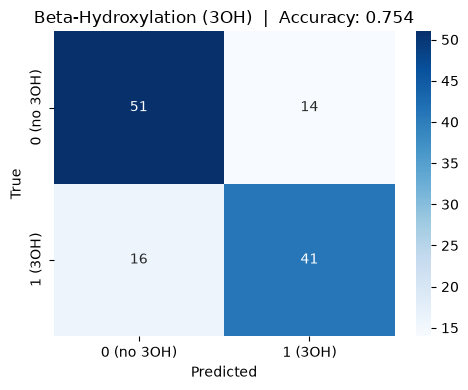

In [4]:
# --- Beta-hydroxylation prediction: 3OH 1 vs 0 ---
# Only evaluate rows where true_3OH is known; pred_3OH always comes from a valid-3OH neighbor
oh_df = results_df[results_df["true_3OH"].notna()].copy()
oh_df["true_3OH"] = oh_df["true_3OH"].astype(int)
oh_df["pred_3OH"] = oh_df["pred_3OH"].astype(int)
print(f"Rows with known 3OH: {len(oh_df)}")

y_true_oh = oh_df["true_3OH"]
y_pred_oh = oh_df["pred_3OH"]

labels_oh = ["0 (no 3OH)", "1 (3OH)"]
cm_oh = confusion_matrix(y_true_oh, y_pred_oh)
acc_oh = accuracy_score(y_true_oh, y_pred_oh)

print("=== Beta-Hydroxylation (3OH) Prediction ===")
print(f"Accuracy: {acc_oh:.3f}")
print(classification_report(y_true_oh, y_pred_oh, target_names=labels_oh))

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_oh, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_oh, yticklabels=labels_oh, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"Beta-Hydroxylation (3OH)  |  Accuracy: {acc_oh:.3f}")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "confusion_3oh.png"), dpi=150)
plt.show()
